<a href="https://colab.research.google.com/github/francji1/01NAEX/blob/main/code/01NAEX_Ex02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01NAEX - Exercise 02: Single-factor experiments and ANOVA

Data and exercises come from D. C. Montgomery: *Design and Analysis of Experiments*, 8th edition, Chapter 3.
Problem numbers follow the 8th edition.

## Learning goals

* Fit the one-way fixed-effects model in `statsmodels`, read the ANOVA table and test $H_0: \mu_1 = \dots = \mu_a$.
* Check the model assumptions with residual plots and formal tests (normality, equal variances, independence).
* Compare treatment means after a significant $F$-test: Fisher's LSD, Tukey's HSD and $p$-value adjustments, and understand what each one controls.
* Compute confidence intervals for treatment means and their differences.
* Determine the sample size (replicates per level) needed to detect a given difference with a given power.


## Example from the lecture: plasma etch rate experiment

Lecture 2 analysed the plasma etching experiment (Montgomery, Example 3.1): the etch rate of a wafer at four levels of RF power
(160, 180, 200, 220 W), five replicates per level, 20 runs in random order. We repeat the analysis in Python:
- explore and visualise the raw data,
- fit the one-way ANOVA model (and, for comparison, a model with the run index as a second factor),
- inspect the residuals and test the assumptions,
- compare the treatment means (Fisher's LSD, Tukey's HSD), and
- evaluate the power of the design for several numbers of replicates.

In [1]:
# Core scientific Python stack for the example
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import OLSInfluence
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.power import FTestAnovaPower
from statsmodels.graphics.gofplots import qqplot

sns.set_theme(style="whitegrid")
np.set_printoptions(suppress=True)


In [2]:
# Load the plasma etch rate data used in the lecture example
ETCH_URL = "https://raw.githubusercontent.com/francji1/01NAEX/main/data/etchrate.txt"
etch_rate = pd.read_csv(ETCH_URL, sep=r"\s+")

# Create categorical views that will be useful for the formulas
etch_rate = etch_rate.assign(
    Power=etch_rate["RF"].astype("category"),
    Run=etch_rate["run"].astype("category")
)

print("Rows, columns:", etch_rate.shape)
display(etch_rate.head())
etch_rate.describe(include="all")


Rows, columns: (20, 5)


,RF,run,rate,Power,Run
0,160,1,575,160,1
1,160,2,542,160,2
2,160,3,530,160,3
3,160,4,539,160,4
4,160,5,570,160,5


,RF,run,rate,Power,Run
count,20.000000,20.000000,20.000000,20.0,20.0
unique,NaN,NaN,NaN,4.0,5.0
top,NaN,NaN,NaN,160.0,1.0
freq,NaN,NaN,NaN,5.0,4.0
mean,190.000000,3.000000,617.750000,NaN,NaN
std,22.941573,1.450953,61.648302,NaN,NaN
min,160.000000,1.000000,530.000000,NaN,NaN
25%,175.000000,2.000000,573.750000,NaN,NaN
50%,190.000000,3.000000,605.000000,NaN,NaN
75%,205.000000,4.000000,659.500000,NaN,NaN


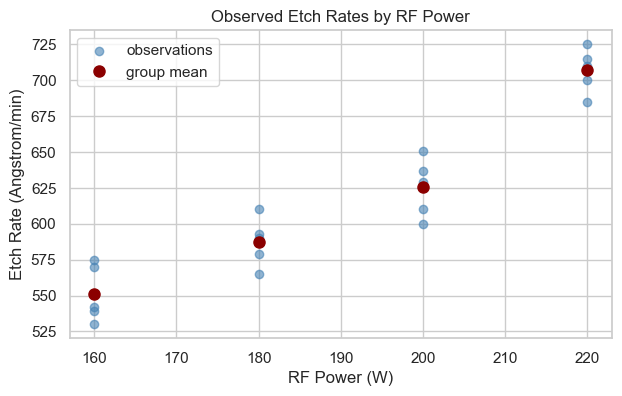

In [3]:
# Visual summary: scatter of observed rates with group means highlighted
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(etch_rate["RF"], etch_rate["rate"], color="steelblue", alpha=0.6, label="observations")
(
    etch_rate.groupby("RF")["rate"].mean()
    .plot(marker="o", color="darkred", linewidth=0, markersize=8, label="group mean", ax=ax)
)
ax.set_xlabel("RF Power (W)")
ax.set_ylabel("Etch Rate (Angstrom/min)")
ax.set_title("Observed Etch Rates by RF Power")
ax.legend()
plt.show()


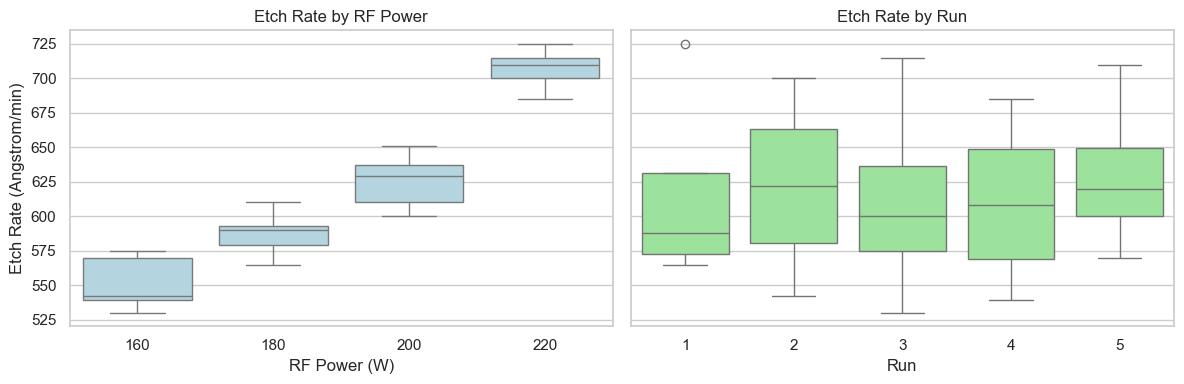

In [4]:
# Boxplots by RF power and by run index (the run index is not a designed block, it only shows that there is no run-to-run drift)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

sns.boxplot(data=etch_rate, x="Power", y="rate", ax=axes[0], color="lightblue")
axes[0].set_title("Etch Rate by RF Power")
axes[0].set_xlabel("RF Power (W)")
axes[0].set_ylabel("Etch Rate (Angstrom/min)")

sns.boxplot(data=etch_rate, x="Run", y="rate", ax=axes[1], color="lightgreen")
axes[1].set_title("Etch Rate by Run")
axes[1].set_xlabel("Run")

plt.tight_layout()
plt.show()


In [5]:
# Fit single-factor and two-factor ANOVA models used in the lecture
model_power = ols("rate ~ C(Power)", data=etch_rate).fit()
model_power_no_intercept = ols("rate ~ C(Power) - 1", data=etch_rate).fit()
model_power_run = ols("rate ~ C(Power) + C(Run)", data=etch_rate).fit()

print(model_power.summary())


                            OLS Regression Results                            
Dep. Variable:                   rate   R-squared:                       0.926
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                     66.80
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           2.88e-09
Time:                        10:47:40   Log-Likelihood:                -84.250
No. Observations:                  20   AIC:                             176.5
Df Residuals:                      16   BIC:                             180.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
Intercept         551.2000      8.169     

In [6]:
# ANOVA tables (type II sums of squares) for both models
anova_power = sm.stats.anova_lm(model_power, typ=2)
anova_power_run = sm.stats.anova_lm(model_power_run, typ=2)

display(anova_power)
display(anova_power_run)

# Direct comparison of the nested models (Power-only vs Power + Run)
display(sm.stats.anova_lm(model_power, model_power_run))


,sum_sq,df,F,PR(>F)
C(Power),66870.55,3.0,66.797073,2.882866e-09
Residual,5339.20,16.0,NaN,NaN


,sum_sq,df,F,PR(>F)
C(Power),66870.55,3.0,62.369063,1.368674e-07
C(Run),1050.50,4.0,0.734838,5.856737e-01
Residual,4288.70,12.0,NaN,NaN


,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,16.0,5339.2,0.0,NaN,NaN,NaN
1,12.0,4288.7,4.0,1050.5,0.734838,0.585674


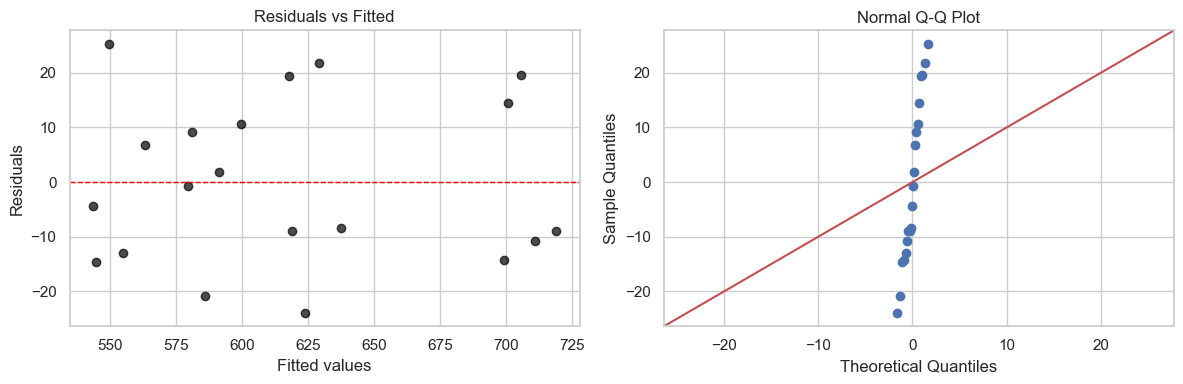

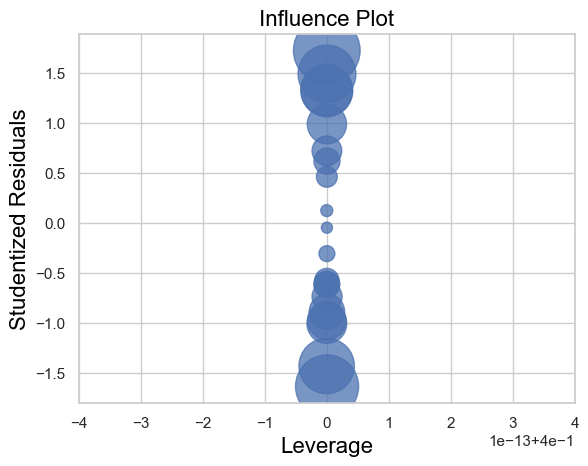

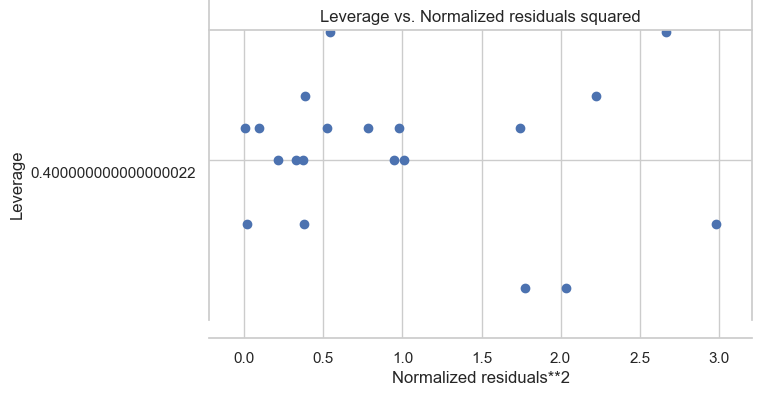

In [7]:
# Regression diagnostics mirroring the lecture content
residuals = model_power_run.resid
fitted = model_power_run.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted, residuals, color="black", alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Fitted")

qqplot(residuals, line="45", ax=axes[1])
axes[1].set_title("Normal Q-Q Plot")

plt.tight_layout()
plt.show()

influence = OLSInfluence(model_power_run)
fig = influence.plot_influence(figsize=(8, 6))
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sm.graphics.plot_leverage_resid2(model_power_run, ax=ax)
plt.show()


In [8]:
# Formal tests from the lecture: normality of residuals, equal variances across power levels, heteroscedasticity, autocorrelation
s_w, s_p = stats.shapiro(residuals)
levene_stat, levene_p = stats.levene(
    *[group["rate"].to_numpy(dtype=float) for _, group in etch_rate.groupby("Power", observed=True)]
)
bartlett_stat, bartlett_p = stats.bartlett(
    *[group["rate"].to_numpy(dtype=float) for _, group in etch_rate.groupby("Power", observed=True)]
)

bp_stat, bp_p, _, _ = het_breuschpagan(residuals, model_power_run.model.exog)
dw_stat = sm.stats.durbin_watson(residuals)

print(f"Shapiro-Wilk (residuals) W = {s_w:.4f}, p-value: {s_p:.3f}")
print(f"Levene (Brown-Forsythe) F = {levene_stat:.4f}, p-value: {levene_p:.3f}")
print(f"Bartlett K^2 = {bartlett_stat:.4f}, p-value: {bartlett_p:.3f}")
print(f"Breusch-Pagan p:     {bp_p:.3f}")
print(f"Durbin-Watson stat:  {dw_stat:.3f}")


Shapiro-Wilk (residuals) W = 0.9465, p-value: 0.317
Levene (Brown-Forsythe) F = 0.1959, p-value: 0.898
Bartlett K^2 = 0.4335, p-value: 0.933
Breusch-Pagan p:     0.038
Durbin-Watson stat:  2.854


 Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj   lower    upper   reject
------------------------------------------------------
   160    180     36.2 0.0294   3.1456  69.2544   True
   160    200     74.2    0.0  41.1456 107.2544   True
   160    220    155.8    0.0 122.7456 188.8544   True
   180    200     38.0 0.0216   4.9456  71.0544   True
   180    220    119.6    0.0  86.5456 152.6544   True
   200    220     81.6    0.0  48.5456 114.6544   True
------------------------------------------------------


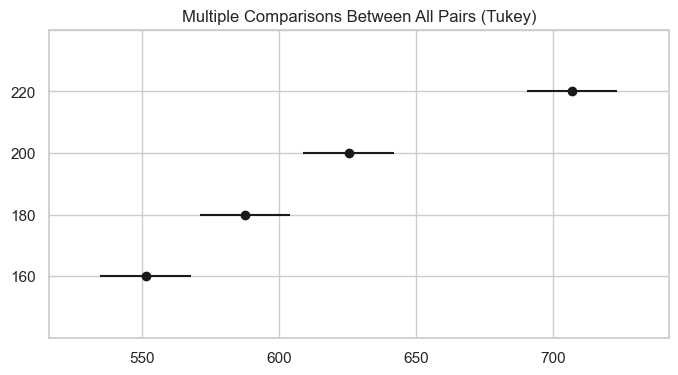

In [9]:
# Tukey HSD multiple comparisons (as demonstrated in the lecture)
tukey = pairwise_tukeyhsd(endog=etch_rate["rate"], groups=etch_rate["Power"], alpha=0.05)
print(tukey)
fig = tukey.plot_simultaneous(figsize=(8, 4))
plt.show()


In [10]:
# Fisher's LSD for the Power-only model (the lecture uses MSE = 333.7 with 16 error df, LSD = 24.49)
means = etch_rate.groupby("Power", observed=True)["rate"].mean()
counts = etch_rate.groupby("Power", observed=True)["rate"].count()
mse = anova_power.loc["Residual", "sum_sq"] / anova_power.loc["Residual", "df"]
df_error = anova_power.loc["Residual", "df"]

alpha = 0.05
t_crit = stats.t.ppf(1 - alpha / 2, df_error)
lsd = t_crit * np.sqrt(2 * mse / counts.iloc[0])          # balanced design: all n_i equal
print(f"MSE = {mse:.1f}, error df = {df_error:.0f}, t = {t_crit:.3f}, LSD (alpha = {alpha}) = {lsd:.2f}")
print("Group means (Angstrom/min):"); print(means)

# all pairwise comparisons: |difference| > LSD means the two means differ
rows = []
levels = list(means.index)
for i in range(len(levels)):
    for j in range(i + 1, len(levels)):
        diff = means.iloc[j] - means.iloc[i]
        rows.append({"pair": f"{levels[j]} - {levels[i]}", "difference": diff, "|diff| > LSD": abs(diff) > lsd})
display(pd.DataFrame(rows))

MSE = 333.7, error df = 16, t = 2.120, LSD (alpha = 0.05) = 24.49
Group means (Angstrom/min):
Power
160    551.2
180    587.4
200    625.4
220    707.0
Name: rate, dtype: float64


,pair,difference,|diff| > LSD
0,180 - 160,36.2,True
1,200 - 160,74.2,True
2,220 - 160,155.8,True
3,200 - 180,38.0,True
4,220 - 180,119.6,True
5,220 - 200,81.6,True


,n per group,Phi^2,power
0,4,4.500,0.606
1,5,5.625,0.805
2,6,6.750,0.915
3,7,7.875,0.967
4,8,9.000,0.988
5,9,10.125,0.996
6,10,11.250,0.999


Cohen's f = 1.061; replicates per level for power 0.9: 6 (exact 5.81)


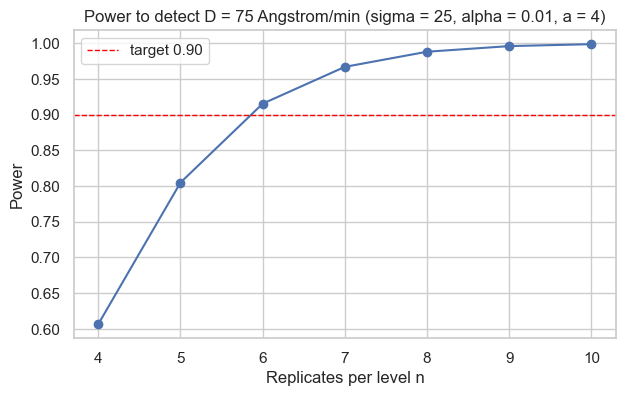

In [11]:
# Sample size: power of the one-way ANOVA F-test for n replicates per level (lecture: D = 75, sigma = 25, alpha = 0.01)
power_analysis = FTestAnovaPower()
alpha = 0.01
sigma = 25          # pilot estimate of the standard deviation
max_diff = 75       # we want to detect two means at least D = 75 Angstrom/min apart
k = 4               # number of levels

# Least favourable configuration: two means D apart, the rest at the overall mean ->
# sum (mu_i - mu)^2 = D^2 / 2, Cohen's f = sqrt(sum (mu_i - mu)^2 / k) / sigma, Phi^2 = n * D^2 / (2 * k * sigma^2)
cohen_f = (max_diff / sigma) * np.sqrt(1 / (2 * k))

sample_sizes = np.arange(4, 11)
power_values = [power_analysis.power(effect_size=cohen_f, nobs=n * k, alpha=alpha, k_groups=k) for n in sample_sizes]
power_df = pd.DataFrame({"n per group": sample_sizes, "Phi^2": sample_sizes * max_diff**2 / (2 * k * sigma**2), "power": power_values})
display(power_df.round(3))

n_needed = power_analysis.solve_power(effect_size=cohen_f, alpha=alpha, power=0.9, k_groups=k) / k
print(f"Cohen's f = {cohen_f:.3f}; replicates per level for power 0.9: {np.ceil(n_needed):.0f} (exact {n_needed:.2f})")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sample_sizes, power_values, marker="o")
ax.set_xlabel("Replicates per level n"); ax.set_ylabel("Power")
ax.set_title("Power to detect D = 75 Angstrom/min (sigma = 25, alpha = 0.01, a = 4)")
ax.axhline(0.9, color="red", linestyle="--", linewidth=1, label="target 0.90")
ax.legend(); plt.show()

## Assignment

* Run the notebook above and make sure you understand each step.
* Solve the following problems from Montgomery, *Design and Analysis of Experiments* (8th edition), Chapter 3: **3.7, 3.8, 3.9, 3.10, 3.18 and 3.19**. Start in class and finish at home.
* For every test state the hypotheses, report the test statistic, its $p$-value and your decision; for comparisons of means say which procedure you use and why; check the assumptions with residual plots; end each problem with a conclusion in one or two sentences.
* Submit your solved notebook as a pull request into the `HW/` folder of the course repository, named
  `HW/01NAEX_Ex02_HW_<Surname>.ipynb` (see `HW/README.md`). **Deadline: Sunday 11 October 2026** (the next lecture is on 12 October).


### Problem 3.7: Portland cement tensile strength
The tensile strength of Portland cement is being studied. Four different mixing techniques can be used economically; four replicates per technique were collected in a completely randomized design (strength in lb/in$^2$).


In [12]:
# Data for Problem 3.7
ex03_7 = pd.read_csv(
    "https://raw.githubusercontent.com/francji1/01NAEX/main/data/Ex03_7.csv",
    sep=";"
)
ex03_7 = ex03_7.assign(Technique=ex03_7["Technique"].astype("category"))
cement = ex03_7.rename(columns={"Tensile_Strength": "strength"})
cement.head()


,Technique,strength
0,1,3129
1,1,3000
2,1,2865
3,1,2890
4,2,3200


**Question 1.** Construct graphical displays that compare the mean tensile strengths for the four mixing techniques.

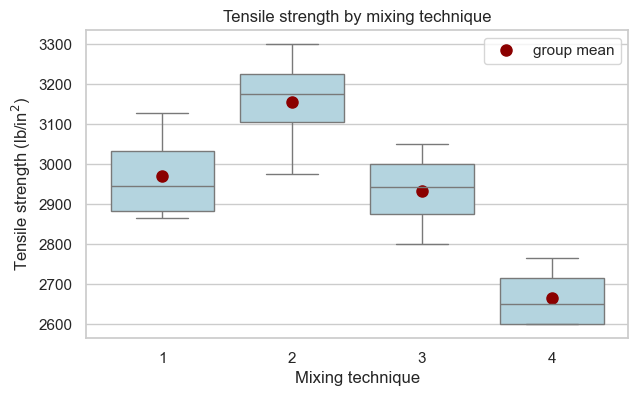

Technique
1    2971.0
2    3156.2
3    2933.8
4    2666.2
Name: strength, dtype: float64


In [13]:
means_c = cement.groupby("Technique", observed=True)["strength"].mean()

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=cement, x="Technique", y="strength", ax=ax, color="lightblue")
ax.plot(range(4), means_c.values, "o", color="darkred", markersize=8, label="group mean")
ax.set_xlabel("Mixing technique"); ax.set_ylabel("Tensile strength (lb/in$^2$)")
ax.set_title("Tensile strength by mixing technique"); ax.legend()
plt.show()

print(means_c.round(1))

Technique 4 gives clearly the lowest strength and technique 2 the highest. Techniques 1 and 3 are close to each other.
The spread inside each technique is similar.

**Question 2.** Test at alpha = 0.05 whether mixing technique affects tensile strength.

**Hypotheses.** $H_0: \mu_1 = \mu_2 = \mu_3 = \mu_4$ (mixing technique has no effect), $H_1$: at least one mean is different.
One-way ANOVA $F$-test, $F_0 = MS_{\text{Treatments}} / MS_E$ with $(a-1,\ N-a) = (3,\ 12)$ degrees of freedom.

In [14]:
model_c = ols("strength ~ C(Technique)", data=cement).fit()
anova_c = sm.stats.anova_lm(model_c, typ=2)
display(anova_c)

mse_c, dfe_c = model_c.mse_resid, model_c.df_resid
print(f"MSE = {mse_c:.1f}, error df = {dfe_c:.0f}")
print(f"F = {anova_c.loc['C(Technique)', 'F']:.2f}, p = {anova_c.loc['C(Technique)', 'PR(>F)']:.4f}")

,sum_sq,df,F,PR(>F)
C(Technique),489740.1875,3.0,12.728107,0.000489
Residual,153908.2500,12.0,NaN,NaN


MSE = 12825.7, error df = 12
F = 12.73, p = 0.0005


**Decision.** $F_0 = 12.73$ on $(3, 12)$ df, $P = 0.0005 < 0.05$. We **reject $H_0$**: mixing technique affects the mean tensile strength.

**Question 3.** Use Fisher's LSD method with alpha = 0.05 to make pairwise comparisons between techniques.

**Procedure.** The $F$-test was significant, so we compare the pairs of means. Fisher's LSD (as asked) tests each pair with a $t$-test that uses the pooled $MS_E$ on 12 df:
$LSD = t_{0.025,\,12}\sqrt{2\,MS_E/n}$. Two means differ if $|\bar y_i - \bar y_j| > LSD$.

In [15]:
def lsd_table(means, lsd):
    # all pairwise differences of group means compared with the LSD
    rows, levels = [], list(means.index)
    for i in range(len(levels)):
        for j in range(i + 1, len(levels)):
            diff = means.iloc[j] - means.iloc[i]
            rows.append({"pair": f"{levels[j]} - {levels[i]}", "difference": round(diff, 2), "|diff| > LSD": abs(diff) > lsd})
    return pd.DataFrame(rows)

n_c = 4
alpha = 0.05
t_c = stats.t.ppf(1 - alpha / 2, dfe_c)
lsd_c = t_c * np.sqrt(2 * mse_c / n_c)
print(f"t = {t_c:.3f}, LSD = {lsd_c:.1f} lb/in^2")
display(lsd_table(means_c, lsd_c))

t = 2.179, LSD = 174.5 lb/in^2


,pair,difference,|diff| > LSD
0,2 - 1,185.25,True
1,3 - 1,-37.25,False
2,4 - 1,-304.75,True
3,3 - 2,-222.50,True
4,4 - 2,-490.00,True
5,4 - 3,-267.50,True


$LSD = 174.5$. Pairs that differ: 2–1, 4–1, 3–2, 4–2, 4–3. The only pair without a significant difference is 1–3 (difference 37, far below the LSD).
So technique 4 is weaker than all others and technique 2 is stronger than all others. For techniques 1 and 3 the data show no difference, but this does not mean they are equal: with four observations per technique, any difference smaller than the LSD (174) could not be detected.
Note that 2–1 (185) is only a little above the LSD.

**Question 4.** Construct a normal probability plot of the residuals. Does the normality assumption appear reasonable?

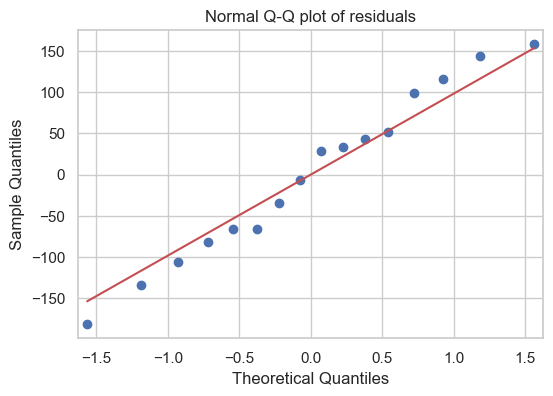

Shapiro-Wilk (residuals): W = 0.9705, p = 0.846


In [16]:
resid_c = model_c.resid

fig, ax = plt.subplots(figsize=(6, 4))
qqplot(resid_c, line="s", ax=ax)
ax.set_title("Normal Q-Q plot of residuals")
plt.show()

w, p = stats.shapiro(resid_c)
print(f"Shapiro-Wilk (residuals): W = {w:.4f}, p = {p:.3f}")

The points lie close to the line and Shapiro-Wilk does not reject normality ($p = 0.85$). The normality assumption is reasonable.

**Question 5.** Plot the residuals versus the fitted tensile strength and comment.

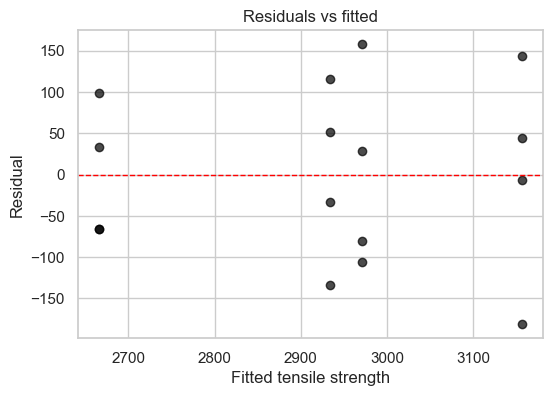

Technique
1    120.6
2    136.0
3    108.3
4     81.0
Name: sd, dtype: float64


In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(model_c.fittedvalues, resid_c, color="black", alpha=0.7)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Fitted tensile strength"); ax.set_ylabel("Residual")
ax.set_title("Residuals vs fitted")
plt.show()

print(cement.groupby("Technique", observed=True)["strength"].std().round(1).rename("sd"))

There is no pattern. The spread of the residuals is about the same at all four fitted values (group standard deviations 81 to 136),
so the constant-variance assumption is acceptable. Technique 4 has a slightly smaller spread, but with $n = 4$ this means little.

**Question 6.** Prepare a scatter plot of the raw observations to aid interpretation.

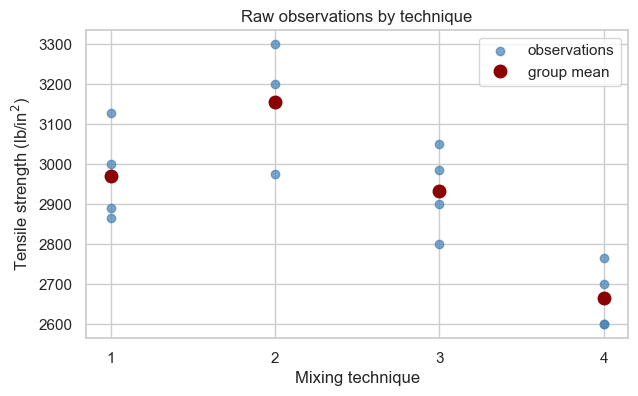

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(cement["Technique"].astype(int), cement["strength"], color="steelblue", alpha=0.7, label="observations")
ax.plot([1, 2, 3, 4], means_c.values, "o", color="darkred", markersize=9, label="group mean")
ax.set_xticks([1, 2, 3, 4]); ax.set_xlabel("Mixing technique"); ax.set_ylabel("Tensile strength (lb/in$^2$)")
ax.set_title("Raw observations by technique"); ax.legend()
plt.show()

The plot shows the same picture as the LSD table: all four values of technique 4 lie below every value of techniques 1 and 2,
techniques 1 and 3 overlap almost completely, and technique 2 is the highest but overlaps a little with technique 1.

**Conclusion.** Mixing technique affects tensile strength ($F = 12.73$, $P = 0.0005$). Technique 4 is clearly the weakest, technique 2 the strongest,
and the data cannot decide whether techniques 1 and 3 differ.


### Problems 3.8 and 3.9: follow-up comparisons for the cement data
We revisit the Portland cement experiment to explore multiple comparisons and confidence intervals.


**Question 1.** Rework the pairwise comparisons using Tukey's test with alpha = 0.05. Do the conclusions match the graphical procedure and Fisher's LSD?

**Procedure.** Tukey's HSD compares all pairs at once and keeps the family-wise error rate at $\alpha = 0.05$
(the chance of *any* false positive among the six comparisons). It uses the studentized range: two means differ if
$|\bar y_i - \bar y_j| > q_{0.05}(a, N-a)\sqrt{MS_E/n}$.

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
group1 group2 meandiff p-adj    lower     upper   reject
--------------------------------------------------------
     1      2   185.25 0.1494  -52.5003  423.0003  False
     1      3   -37.25 0.9653 -275.0003  200.5003  False
     1      4  -304.75 0.0116 -542.5003  -66.9997   True
     2      3   -222.5 0.0693 -460.2503   15.2503  False
     2      4   -490.0 0.0003 -727.7503 -252.2497   True
     3      4   -267.5 0.0262 -505.2503  -29.7497   True
--------------------------------------------------------


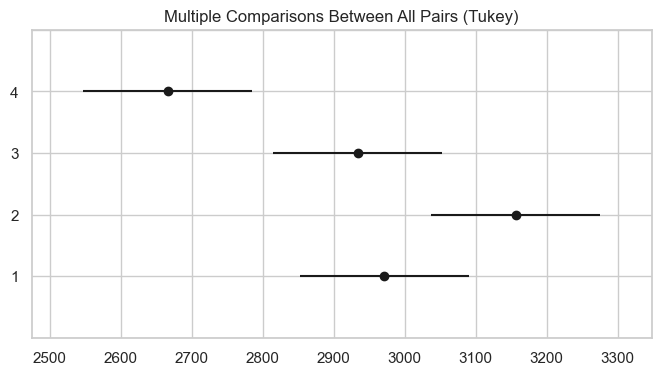

Tukey critical difference HSD = 237.8   (Fisher's LSD was 174.5)


In [19]:
tukey_c = pairwise_tukeyhsd(endog=cement["strength"], groups=cement["Technique"], alpha=0.05)
print(tukey_c)
fig = tukey_c.plot_simultaneous(figsize=(8, 4))
plt.show()

from statsmodels.stats.libqsturng import qsturng
hsd_c = qsturng(0.95, 4, dfe_c) * np.sqrt(mse_c / n_c)
print(f"Tukey critical difference HSD = {hsd_c:.1f}   (Fisher's LSD was {lsd_c:.1f})")

Tukey finds only three differences: 1–4, 2–4 and 3–4. The pairs 1–2 ($p = 0.15$) and 2–3 ($p = 0.07$) are **not** significant,
although Fisher's LSD called them different. The critical difference is 237.8 for Tukey against 174.5 for the LSD.

So the conclusions do not fully match. The graphical display and the LSD separate technique 2 from techniques 1 and 3.
Tukey separates only technique 4 from the rest. The common part is clear: technique 4 is the weakest.


**Question 2.** Explain the difference between Tukey's procedure and Fisher's LSD.


**Fisher's LSD** tests every pair with an ordinary $t$-test at $\alpha = 0.05$, using the pooled $MS_E$. It controls the error rate
**per comparison**. With six comparisons and all null hypotheses true, the chance of at least one false positive is up to
$1 - 0.95^6 \approx 0.26$. It has high power and is simple, but it is risky when many pairs are compared.

**Tukey's HSD** uses the studentized range distribution, which describes the largest difference among $a$ sample means.
It controls the **family-wise** error rate: the chance of any false positive among all pairs is $\alpha$. The price is a larger critical
difference (237.8 vs 174.5 here), so it has lower power and finds fewer differences.

In short: LSD is for a few comparisons planned in advance, Tukey is for comparing all pairs. For the cement data, where all six pairs are
compared, Tukey is the safer choice.

**Question 3.** Find 95 percent confidence intervals for each technique mean and for the difference between techniques 1 and 3. How do these intervals aid interpretation?

In [20]:
se_mean_c = np.sqrt(mse_c / n_c)
ci_means_c = pd.DataFrame({
    "mean": means_c,
    "lower": means_c - t_c * se_mean_c,
    "upper": means_c + t_c * se_mean_c,
})
print(f"95% CI for a treatment mean: mean ± {t_c * se_mean_c:.1f}")
display(ci_means_c.round(1))

diff_13 = means_c[1] - means_c[3]
se_diff_c = np.sqrt(2 * mse_c / n_c)
print(f"95% CI for mu1 - mu3: {diff_13:.1f} ± {t_c * se_diff_c:.1f} -> ({diff_13 - t_c * se_diff_c:.1f}, {diff_13 + t_c * se_diff_c:.1f})")

95% CI for a treatment mean: mean ± 123.4


,mean,lower,upper
Technique,,,
1,2971.0,2847.6,3094.4
2,3156.2,3032.9,3279.6
3,2933.8,2810.4,3057.1
4,2666.2,2542.9,2789.6


95% CI for mu1 - mu3: 37.2 ± 174.5 -> (-137.2, 211.7)


Each treatment mean has a 95 % interval of $\bar y_i \pm 123$ lb/in$^2$ ($t_{0.025,12}\sqrt{MS_E/n}$). The interval for $\mu_1 - \mu_3$ is
$(-137,\ 212)$. It contains zero, so a zero difference is consistent with the data, which agrees with LSD and Tukey. But the interval is 350 units wide: it also allows technique 1 to be 200 stronger or 130 weaker than technique 3. The data do not show a difference, and they cannot rule one out either.

The intervals show how large the uncertainty is: a half-width of 123 for a mean and 174 for a difference, with differences between techniques 1, 2 and 3
of only 37 to 222. This explains why the methods disagree about technique 2.

**Conclusion.** Only technique 4 is different from all others with certainty. Whether technique 2 is better than 1 and 3 depends on the procedure,
and with four observations per technique the data cannot decide it.


### Problem 3.10: cotton content and fibre strength
A product developer is investigating the tensile strength of a new synthetic fibre. The percentage of cotton in the blend is varied over five levels (15, 20, 25, 30, 35 %) with five replicates per level, run in random order.


In [21]:
# Data for Problem 3.10
ex03_10 = pd.read_csv(
    "https://raw.githubusercontent.com/francji1/01NAEX/main/data/Ex03_10.csv",
    sep=";"
).rename(columns={"Cotton_Weight ": "Cotton_Weight", "Observations": "strength"})
ex03_10 = ex03_10.assign(Cotton_Weight=ex03_10["Cotton_Weight"].astype("category"))
ex03_10.head()


,Cotton_Weight,strength
0,15,7
1,20,12
2,25,14
3,30,19
4,35,7


**Question 1.** Test at alpha = 0.05 whether cotton content affects mean fibre strength.

**Hypotheses.** $H_0: \mu_{15} = \mu_{20} = \mu_{25} = \mu_{30} = \mu_{35}$ (cotton content has no effect), $H_1$: at least one mean differs.
One-way ANOVA $F$-test with $(a-1,\ N-a) = (4,\ 20)$ degrees of freedom.

In [22]:
model_f = ols("strength ~ C(Cotton_Weight)", data=ex03_10).fit()
anova_f = sm.stats.anova_lm(model_f, typ=2)
display(anova_f)

mse_f, dfe_f = model_f.mse_resid, model_f.df_resid
means_f = ex03_10.groupby("Cotton_Weight", observed=True)["strength"].mean()
print(means_f.round(1))
print(f"MSE = {mse_f:.2f}, error df = {dfe_f:.0f}")
print(f"F = {anova_f.loc['C(Cotton_Weight)', 'F']:.2f}, p = {anova_f.loc['C(Cotton_Weight)', 'PR(>F)']:.6f}")

,sum_sq,df,F,PR(>F)
C(Cotton_Weight),475.76,4.0,14.756824,0.000009
Residual,161.20,20.0,NaN,NaN


Cotton_Weight
15     9.8
20    15.4
25    17.6
30    21.6
35    10.8
Name: strength, dtype: float64
MSE = 8.06, error df = 20
F = 14.76, p = 0.000009


**Decision.** $F_0 = 14.76$ on $(4, 20)$ df, $P < 0.0001$. We **reject $H_0$**: cotton content affects the mean fibre strength.

**Question 2.** Use Fisher's LSD (alpha = 0.05) to compare the mean strengths across cotton levels.

**Procedure.** Fisher's LSD as asked, $LSD = t_{0.025,\,20}\sqrt{2\,MS_E/n}$ with $n = 5$.

In [23]:
n_f = 5
t_f = stats.t.ppf(0.975, dfe_f)
lsd_f = t_f * np.sqrt(2 * mse_f / n_f)
print(f"t = {t_f:.3f}, LSD = {lsd_f:.2f}")
display(lsd_table(means_f, lsd_f))

t = 2.086, LSD = 3.75


,pair,difference,|diff| > LSD
0,20 - 15,5.6,True
1,25 - 15,7.8,True
2,30 - 15,11.8,True
3,35 - 15,1.0,False
4,25 - 20,2.2,False
5,30 - 20,6.2,True
6,35 - 20,-4.6,True
7,30 - 25,4.0,True
8,35 - 25,-6.8,True
9,35 - 30,-10.8,True


$LSD = 3.75$. Two pairs show no significant difference: 15–35 (difference 1.0) and 20–25 (2.2). All other pairs differ significantly.
Strength rises from 15 % to 30 % cotton and falls again at 35 %. The groups are $\{15, 35\} < \{20, 25\} < 30$,
where 25 vs 30 (difference 4.0) is only a little above the LSD.

**Question 3.** Analyse residuals and comment on model adequacy.

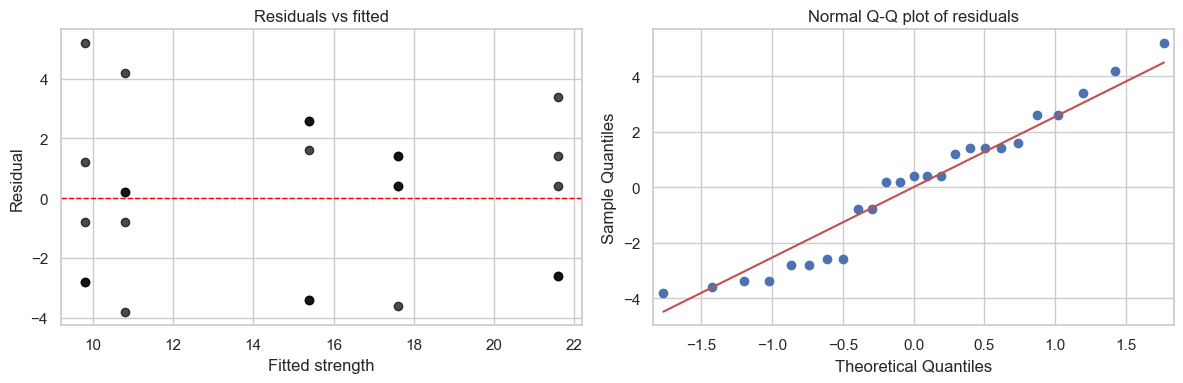

Shapiro-Wilk (residuals): W = 0.9439, p = 0.182
Levene (Brown-Forsythe):  F = 0.3179, p = 0.863


In [24]:
resid_f = model_f.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(model_f.fittedvalues, resid_f, color="black", alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_xlabel("Fitted strength"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs fitted")
qqplot(resid_f, line="s", ax=axes[1])
axes[1].set_title("Normal Q-Q plot of residuals")
plt.tight_layout(); plt.show()

w, p = stats.shapiro(resid_f)
groups_f = [g.to_numpy(float) for _, g in ex03_10.groupby("Cotton_Weight", observed=True)["strength"]]
lev_f = stats.levene(*groups_f, center="median")
print(f"Shapiro-Wilk (residuals): W = {w:.4f}, p = {p:.3f}")
print(f"Levene (Brown-Forsythe):  F = {lev_f.statistic:.4f}, p = {lev_f.pvalue:.3f}")

Residuals vs fitted show no pattern and a similar spread at all five levels. The Q-Q plot is roughly a straight line
(the small steps come from the integer strength values) and Shapiro-Wilk does not reject ($p = 0.18$). Levene's test does not reject equal variances ($p = 0.86$).
The model is adequate.

**Conclusion.** Cotton content affects fibre strength ($F = 14.76$, $P < 0.0001$). Strength is highest at 30 % cotton (mean 21.6) and
35 % cotton is as weak as 15 %.

### Problems 3.18 and 3.19: coating of colour picture tubes

A manufacturer of television sets is interested in the effect on tube conductivity of four different types of coating for colour picture tubes.
A completely randomized experiment is conducted and the following conductivity data are obtained:

| Coating type | Conductivity |
|---|---|
| 1 | 143, 141, 150, 146 |
| 2 | 152, 149, 137, 143 |
| 3 | 134, 136, 132, 127 |
| 4 | 129, 127, 132, 129 |

In [25]:
# Data for Problems 3.18 and 3.19
ex03_18 = pd.read_csv(
    "https://raw.githubusercontent.com/francji1/01NAEX/main/data/Ex03_18.csv",
    sep=";"
)
ex03_18.columns = [c.strip() for c in ex03_18.columns]
ex03_18 = ex03_18.assign(Type=ex03_18["Type"].astype("category"))
ex03_18.head()

,Type,Conductivity
0,1,143
1,1,141
2,1,150
3,1,146
4,2,152


**Question 1.** Is there a difference in conductivity due to coating type? Use alpha = 0.05.

**Hypotheses.** $H_0: \mu_1 = \mu_2 = \mu_3 = \mu_4$ (coating type has no effect), $H_1$: at least one mean differs.
One-way ANOVA $F$-test with $(3,\ 12)$ degrees of freedom.

In [26]:
model_k = ols("Conductivity ~ C(Type)", data=ex03_18).fit()
anova_k = sm.stats.anova_lm(model_k, typ=2)
display(anova_k)

mse_k, dfe_k = model_k.mse_resid, model_k.df_resid
print(f"MSE = {mse_k:.2f}, error df = {dfe_k:.0f}")
print(f"F = {anova_k.loc['C(Type)', 'F']:.2f}, p = {anova_k.loc['C(Type)', 'PR(>F)']:.4f}")

,sum_sq,df,F,PR(>F)
C(Type),844.6875,3.0,14.301587,0.000288
Residual,236.2500,12.0,NaN,NaN


MSE = 19.69, error df = 12
F = 14.30, p = 0.0003


**Decision.** $F_0 = 14.30$ on $(3, 12)$ df, $P = 0.0003 < 0.05$. We **reject $H_0$**: coating type affects conductivity.

**Question 2.** Estimate the overall mean and the treatment effects.

In [27]:
n_k, N_k = 4, len(ex03_18)
grand_k = ex03_18["Conductivity"].mean()
means_k = ex03_18.groupby("Type", observed=True)["Conductivity"].mean()
effects_k = means_k - grand_k                      # tau_i = ybar_i. - ybar..

print(f"grand mean = {grand_k:.3f}")
display(pd.DataFrame({"mean": means_k, "effect tau_i": effects_k}).round(3))
print(f"sum of effects = {effects_k.sum():.1e}")
print(f"SE of a treatment mean = {np.sqrt(mse_k / n_k):.3f}, SE of an effect = {np.sqrt(mse_k * (1 / n_k - 1 / N_k)):.3f}")

grand mean = 137.938


,mean,effect tau_i
Type,,
1,145.00,7.062
2,145.25,7.312
3,132.25,-5.688
4,129.25,-8.688


sum of effects = 0.0e+00
SE of a treatment mean = 2.219, SE of an effect = 1.921


$\hat\mu = 137.94$. The treatment effects are $\hat\tau_1 = 7.06$, $\hat\tau_2 = 7.31$, $\hat\tau_3 = -5.69$, $\hat\tau_4 = -8.69$ (they sum to zero).
Coatings 1 and 2 are above the overall mean, coatings 3 and 4 below it.

**Question 3.** Compute a 95% confidence interval for the mean of coating type 4 and a 99% confidence interval for the mean difference between coatings 1 and 4.

In [28]:
t95_k = stats.t.ppf(0.975, dfe_k)
t99_k = stats.t.ppf(0.995, dfe_k)
se_mean_k = np.sqrt(mse_k / n_k)
se_diff_k = np.sqrt(2 * mse_k / n_k)

m4 = means_k[4]
d14 = means_k[1] - means_k[4]
print(f"95% CI for mu4:       {m4:.2f} ± {t95_k * se_mean_k:.2f} -> ({m4 - t95_k * se_mean_k:.2f}, {m4 + t95_k * se_mean_k:.2f})")
print(f"99% CI for mu1 - mu4: {d14:.2f} ± {t99_k * se_diff_k:.2f} -> ({d14 - t99_k * se_diff_k:.2f}, {d14 + t99_k * se_diff_k:.2f})")

95% CI for mu4:       129.25 ± 4.83 -> (124.42, 134.08)
99% CI for mu1 - mu4: 15.75 ± 9.58 -> (6.17, 25.33)


$\mu_4 \in (124.4,\ 134.1)$ with 95 % confidence. $\mu_1 - \mu_4 \in (6.2,\ 25.3)$ with 99 % confidence: the interval does not contain zero,
so coating 1 has a higher conductivity than coating 4, by at least 6 units.

**Question 4.** Test all pairs of means using the Fisher LSD method with alpha = 0.05.

**Procedure.** Fisher's LSD as asked, $LSD = t_{0.025,\,12}\sqrt{2\,MS_E/n}$ with $n = 4$.

In [29]:
lsd_k = t95_k * np.sqrt(2 * mse_k / n_k)
print(f"LSD = {lsd_k:.2f}")
display(lsd_table(means_k, lsd_k))

LSD = 6.84


,pair,difference,|diff| > LSD
0,2 - 1,0.25,False
1,3 - 1,-12.75,True
2,4 - 1,-15.75,True
3,3 - 2,-13.00,True
4,4 - 2,-16.00,True
5,4 - 3,-3.00,False


$LSD = 6.84$. Pairs that differ: 1–3, 1–4, 2–3, 2–4. Pairs with no significant difference: 1–2 (difference 0.25) and 3–4 (3.0).
There are two groups: coatings 1 and 2 with high conductivity (about 145) and coatings 3 and 4 with low conductivity (about 130).

**Question 5.** Use the graphical method from Section 3.5.3 of Montgomery (plot the means with a scaled $t$ distribution) to compare the means. Which coating type produces the highest conductivity?

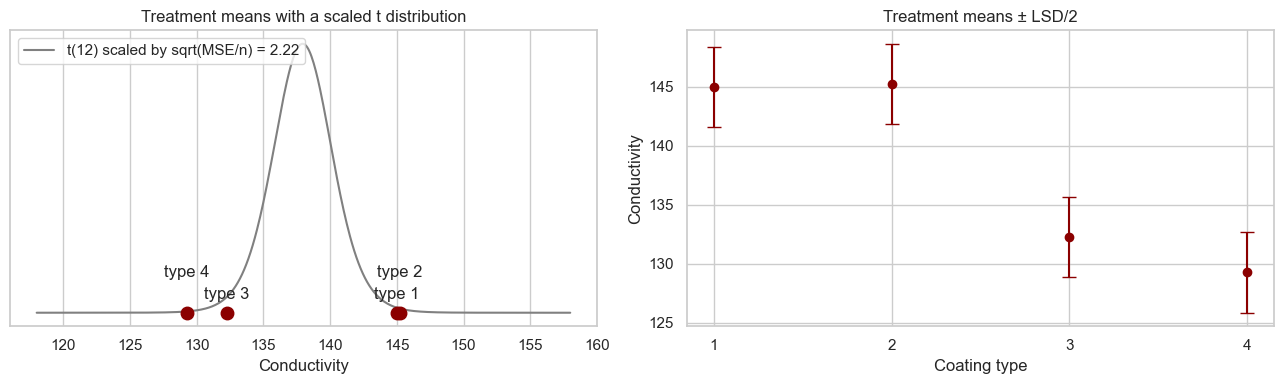

In [30]:
scale_k = np.sqrt(mse_k / n_k)      # standard deviation of a treatment mean

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# left: the four means on the axis and a t distribution scaled by sqrt(MSE/n) (slide it along the axis)
x = np.linspace(118, 158, 500)
axes[0].plot(x, stats.t.pdf((x - grand_k) / scale_k, dfe_k) / scale_k, color="gray",
             label=f"t({dfe_k:.0f}) scaled by sqrt(MSE/n) = {scale_k:.2f}")
for typ, m in means_k.items():
    axes[0].plot(m, 0, "o", color="darkred", markersize=9)
    dy = 10 if typ in (1, 3) else 26          # stagger the labels so they do not overlap
    axes[0].annotate(f"type {typ}", (m, 0), textcoords="offset points", xytext=(0, dy), ha="center")
axes[0].set_xlabel("Conductivity"); axes[0].set_yticks([])
axes[0].set_title("Treatment means with a scaled t distribution"); axes[0].legend(loc="upper left")

# right: means with ± LSD/2 bars (bars that do not overlap = significant difference)
axes[1].errorbar(means_k.index.astype(int), means_k.values, yerr=lsd_k / 2, fmt="o", color="darkred", capsize=5)
axes[1].set_xticks([1, 2, 3, 4]); axes[1].set_xlabel("Coating type"); axes[1].set_ylabel("Conductivity")
axes[1].set_title("Treatment means ± LSD/2")
plt.tight_layout(); plt.show()

The curve is the sampling distribution of one treatment mean (standard deviation $\sqrt{MS_E/n} = 2.22$). Means 1 and 2 (145.0, 145.25) fit under
one position of the curve, and so do means 3 and 4 (132.25, 129.25). The two pairs are about 13 to 16 units apart, which is more than
five standard deviations of a mean, so one curve cannot cover both pairs. This is the same grouping as the LSD.

The highest conductivity comes from **coating type 2** (145.25), but the data cannot separate it from type 1 (145.0).

**Question 6.** Assuming coating type 4 is currently in use and conductivity should be minimised, what is your recommendation?

Coating type 4 has the lowest mean conductivity (129.25). Type 3 (132.25) is not significantly different from it, and types 1 and 2
are significantly higher (by about 16 units). No coating gives a lower conductivity than the one in use.

**Recommendation:** keep coating type 4. A change to type 3 would bring no proven gain, and types 1 and 2 would make conductivity worse.

**Question 7.** Analyse the residuals and comment on model adequacy.

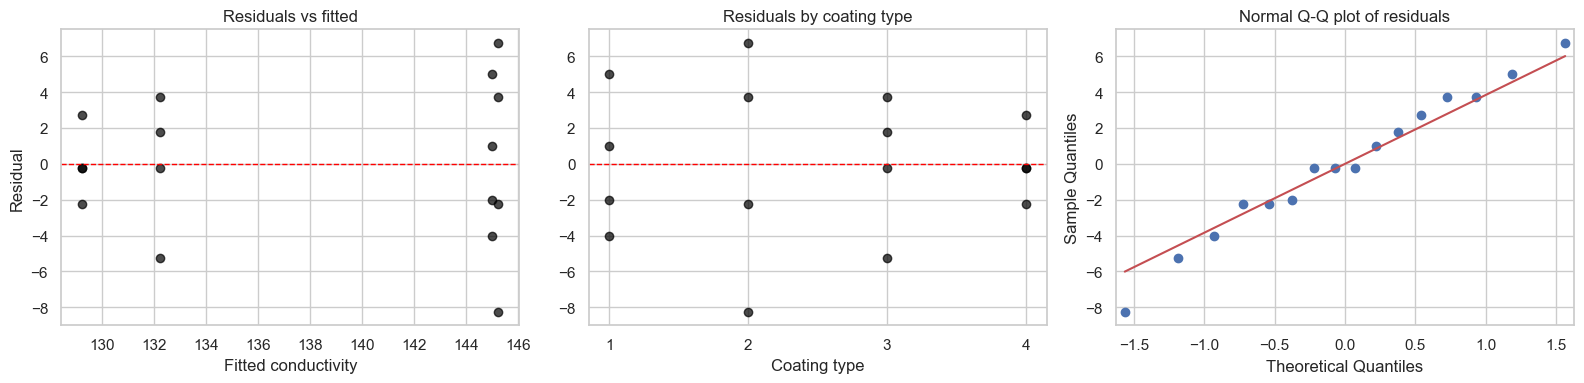

Shapiro-Wilk (residuals): W = 0.9842, p = 0.988
Levene (Brown-Forsythe):  F = 2.2068, p = 0.140
Bartlett:                 K^2 = 3.2944, p = 0.348
Type
1    3.92
2    6.65
3    3.86
4    2.06
Name: sd, dtype: float64


In [31]:
resid_k = model_k.resid

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(model_k.fittedvalues, resid_k, color="black", alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_xlabel("Fitted conductivity"); axes[0].set_ylabel("Residual"); axes[0].set_title("Residuals vs fitted")
axes[1].scatter(ex03_18["Type"].astype(int), resid_k, color="black", alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1)
axes[1].set_xticks([1, 2, 3, 4]); axes[1].set_xlabel("Coating type"); axes[1].set_title("Residuals by coating type")
qqplot(resid_k, line="s", ax=axes[2])
axes[2].set_title("Normal Q-Q plot of residuals")
plt.tight_layout(); plt.show()

w, p = stats.shapiro(resid_k)
groups_k = [g.to_numpy(float) for _, g in ex03_18.groupby("Type", observed=True)["Conductivity"]]
lev_k = stats.levene(*groups_k, center="median")
bart_k = stats.bartlett(*groups_k)
print(f"Shapiro-Wilk (residuals): W = {w:.4f}, p = {p:.3f}")
print(f"Levene (Brown-Forsythe):  F = {lev_k.statistic:.4f}, p = {lev_k.pvalue:.3f}")
print(f"Bartlett:                 K^2 = {bart_k.statistic:.4f}, p = {bart_k.pvalue:.3f}")
print(ex03_18.groupby("Type", observed=True)["Conductivity"].std().round(2).rename("sd"))

Residuals vs fitted show no pattern. Coating 2 has the largest spread (sd 6.7) and coating 4 the smallest (2.1), but neither Levene ($p = 0.14$)
nor Bartlett ($p = 0.35$) rejects equal variances, and with four observations per type such differences are expected.
The Q-Q plot is a straight line and Shapiro-Wilk gives $p = 0.99$. The model is adequate.

**Conclusion.** Coating type affects conductivity ($F = 14.30$, $P = 0.0003$). Coatings 1 and 2 give high conductivity (about 145),
coatings 3 and 4 low conductivity (about 130). To keep conductivity low, stay with coating 4.